# 04 · CNN model

A small **1-D convolutional neural network (CNN)** that reads the raw waveform. It is trained with the same session folds as the baseline (notebook 03) and compared against it. Then we try to improve it, judging every change with a scoring method that suits a randomly trained model.

| Part | What |
|---|---|
| 0 | Setup |
| 1 | How we judge the CNN (and why one training run is not enough) |
| 2 | The baseline, measured the same way |
| 3 | The CNN |
| 4 | First CNN vs the baseline |
| 5 | Where the CNN goes wrong |
| 6 | Ten attempts to improve it |
| 7 | Final comparison |
| 8 | Save the results |
| 9 | Summary and next steps |

**Runtime.** Training everything from scratch means 11 settings × 10 seeds × 3 folds = 330 small networks, about 1–2 hours on a laptop CPU. Results are cached in `cache/cnn/` in the data root, keyed by the settings, the files and their folds, so re-running this notebook takes under a minute. If new data arrives or a setting changes, only the affected models are retrained. The code is in `src/ureca/models/cnn.py`.

## 0. Setup

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import torch
import warnings; warnings.filterwarnings("ignore", category=UserWarning)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

from ureca.dataset.loading import CLASSES, FS, TRIGGER, load_index, load_waveforms, fold_split
from ureca.models.features import compute_features, AMPLITUDE, SHAPE
from ureca.evaluate import metrics, confusion, balanced_log_loss, session_balanced_accuracy
from ureca.models.cnn import CNNConfig, SmallCNN, cv_cnn_cached, THREADS
from ureca.config import ensure_dirs
from ureca.plotting import set_style, confusion_plot, NAMES, COLORS, FOLD_COLORS, INK, INK2, GRID, SURFACE

set_style()
files = load_index()
X = load_waveforms(files)
y = files["y"].values
sessions = files["session_id"].values
SEEDS = range(10)

167 waveforms: 167 from cache, 0 read from text


## 1. How we judge the CNN

Notebook 03 chose **macro-F1** of the out-of-fold predictions as the main score. We keep it, so the numbers stay comparable. But a CNN adds a new problem: **its training is random**. The starting weights and the order in which files are drawn depend on a random *seed*. With only 167 files, two seeds can give very different models (part 4 shows how different). One training run is one lucky or unlucky draw, not a measurement.

So in this notebook every model is scored like this:

| Score | What it is | Why |
|---|---|---|
| **macro-F1, mean ± sd over 10 seeds** (main score) | run the whole 3-fold cross-validation 10 times (seeds 0–9), score each run, average | removes the luck of a single seed; the sd shows how much luck there is |
| **macro-F1 of the 10-seed ensemble** | average the 10 models' probabilities for each file, then pick the most likely class | this is the model we would actually use: 10 small networks voting is cheap |
| **Session-balanced accuracy** | the share correct within each recording session, averaged so **every session counts once**, then averaged over classes | one 62-file session that goes wrong as a block costs as much as one 1-file session; it answers "how many recording situations does the model handle?" |
| **Balanced log-loss** | how much probability the model gave to the true class (averaged within each class, then over classes). Lower is better. **1.39 = pure guessing** | rewards being right with confidence and punishes being confidently wrong; it moves smoothly, while F1 only moves when a file flips |
| **PD recall** and **PD precision**, false PD alarms (guardrails) | of the real PDs, the share caught / of the files called PD, the share that really are PD | a missed PD is the costliest error, but a stream of false PD alarms makes a monitoring system useless too |

**When is a change an improvement?** The 10-seed mean macro-F1 must go up by clearly more than its uncertainty (the standard error, sd/√10, is about ±0.04 here), without PD recall, PD precision or log-loss getting worse. Anything smaller is noise.

**One more caution.** We try several CNN variants on the same folds and keep the best. The winner's score is then a little optimistic, because part of its lead is luck that will not repeat. So we keep the list of variants short and show all of them. The honest final test is the **next batch of data**, which no model here has seen.

In [2]:
def scores(p):
    """All scores for one set of out-of-fold probabilities, shape (n_files, 4)."""
    pred = p.argmax(1)
    m = metrics(y, pred)
    return {"macro_f1": m["macro_f1"],
            "session_bal_acc": session_balanced_accuracy(y, pred, sessions),
            "bal_log_loss": balanced_log_loss(y, p),
            **{f"recall_{c}": m[f"recall_{c}"] for c in CLASSES},
            "precision_pd": precision_score(y == 0, pred == 0, zero_division=0),
            "false_pd_alarms": int(((pred == 0) & (y != 0)).sum())}


def summarise(P):
    """P: (n_seeds, n_files, 4) -> (table with one row per seed, scores of the seed ensemble)."""
    return pd.DataFrame([scores(p) for p in P]), scores(P.mean(0))


def row(name, P):
    per_seed, ens = summarise(P)
    return {"model": name,
            "macro_f1 (seed mean)": per_seed["macro_f1"].mean(),
            "± sd": per_seed["macro_f1"].std(),
            "macro_f1 (ensemble)": ens["macro_f1"],
            "session_bal_acc (ensemble)": ens["session_bal_acc"],
            "bal_log_loss (ensemble)": ens["bal_log_loss"],
            "PD precision (ensemble)": ens["precision_pd"],
            "false PD alarms (ensemble)": ens["false_pd_alarms"],
            **{f"recall {NAMES[c]}": ens[f"recall_{c}"] for c in CLASSES}}

## 2. The baseline, measured the same way

The random forest from notebook 03 is random too: each of its 300 trees sees a random sample of the files and features. For a fair comparison we train it with the same 10 seeds. Seed 0 is exactly the model from notebook 03.

In [3]:
F = compute_features(X)[AMPLITUDE + SHAPE].values

def rf_oof(seed):
    p = np.zeros((len(y), len(CLASSES)))
    for k in range(3):
        tr, va = fold_split(files, k)
        rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced",
                                    random_state=seed)
        p[va] = rf.fit(F[tr], y[tr]).predict_proba(F[va])
    return p

P_rf = np.stack([rf_oof(s) for s in SEEDS])
rf_seed, rf_ens = summarise(P_rf)
print(f"seed 0 (= notebook 03): macro-F1 {rf_seed['macro_f1'][0]:.3f}")
rf_seed[["macro_f1", "session_bal_acc", "bal_log_loss"]].T.round(3)

seed 0 (= notebook 03): macro-F1 0.763


,0,1,2,3,4,5,6,7,8,9
macro_f1,0.763,0.754,0.751,0.760,0.741,0.749,0.507,0.743,0.763,0.731
session_bal_acc,0.771,0.766,0.765,0.769,0.752,0.768,0.690,0.768,0.771,0.765
bal_log_loss,0.525,0.517,0.524,0.524,0.509,0.521,0.539,0.518,0.533,0.525


**Explanation:**
- Seed 0 gives **0.763**, the number from notebook 03.
- Nine of the ten seeds land between 0.73 and 0.76. Seed 6 drops to 0.51: in that run the forest misclassifies the 62-file switching-noise session of 1 Sep 10:47 (the heat map in part 5 shows it). So even the baseline is somewhat lucky or unlucky, and its fair score is **0.73 ± 0.08**.
- Balanced log-loss is about **0.52** for every seed: the forest's probabilities (the share of its 300 trees that vote for a class) are cautious and fairly trustworthy.

## 3. The CNN

A **convolutional neural network** slides many small learned filters along the waveform. Each filter is a short pattern detector, at first only 7 samples (56 ns) long, such as "a sharp rising edge" or "a 20 MHz ripple". Each layer combines the patterns of the layer below into longer ones.

Our network (`SmallCNN` in `src/ureca/models/cnn.py`) is deliberately small, because 167 files is very little for a neural network:

```
waveform [1 × 7500] ─► 5 blocks: convolution (7 taps) → batch norm → ReLU → max-pool ÷4
                    ─► average and maximum of each of the 64 channels over time  (128 numbers)
                    ─► dropout → linear layer → 4 class scores → softmax → 4 probabilities
```

| Step | What it does |
|---|---|
| Convolution | 16, then 32, then 64 learned filters per block |
| Batch norm | rescales each channel during training, which keeps training stable |
| ReLU | keeps positive filter responses, sets negative ones to 0 |
| Max-pool ÷4 | keeps the strongest response in every 4 time steps, so the next block covers a 4× longer stretch of time |
| Average + max over time | "how much of this pattern is there overall" and "its strongest single occurrence"; the result no longer depends on *where* in the window a pattern is |
| Dropout 0.3 | in training, randomly zeroes 30% of the 128 numbers, so the model cannot lean on any single one |

Settings of the **first CNN** (the plan from notebook 02, part 8):
- input: crop −10…+50 µs, baseline removed, divided by one fixed number (the median peak of the training files). **Amplitude is kept**, as in the baseline;
- the balanced sampler from notebook 02, so every class is drawn equally often;
- 40 epochs, AdamW optimiser, learning rate rising then falling ("one-cycle");
- **no early stopping.** Stopping where the validation score peaks would let the validation files choose the model, which is a leak.

In [4]:
cfg = CNNConfig()
model = SmallCNN()
L = 7500                                   # crop -10 ... +50 µs at 125 MS/s
h = torch.zeros(1, 1, L)
stages = [("input", 1, L)]
for layer in model.features:
    h = layer(h)
    if isinstance(layer, torch.nn.MaxPool1d):
        stages.append((f"block {len(stages)}", h.shape[1], h.shape[-1]))
arch = pd.DataFrame(stages, columns=["after", "channels", "time steps"])
arch["one step = µs"] = (L / arch["time steps"] / FS * 1e6).round(3)
print(f"trainable parameters: {sum(p.numel() for p in model.parameters()):,}")
print("training settings:", {k: v for k, v in cfg.to_dict().items() if k in
      ["crop", "normalize", "sampler", "epochs", "batch_size", "lr", "weight_decay", "dropout"]})
arch

trainable parameters: 76,372
training settings: {'crop': (-10, 50), 'normalize': 'global', 'sampler': 'class', 'dropout': 0.3, 'epochs': 40, 'batch_size': 32, 'lr': 0.003, 'weight_decay': 0.01}


,after,channels,time steps,one step = µs
0,input,1,7500,0.008
1,block 1,16,1875,0.032
2,block 2,32,468,0.128
3,block 3,64,117,0.513
4,block 4,64,29,2.069
5,block 5,64,7,8.571


**Explanation:** each block divides the number of time steps by 4. After block 5 one step stands for about 8.6 µs, and the whole crop is 7 steps. One output position "sees" about 25 µs of the input. That is shorter than the ~33 µs between switching-noise bursts, which matters in part 5. The network has about **76,000 weights**, several hundred per training file. That is small for a CNN, but still plenty to memorise ~100 training files. It does: on its own training files it reaches macro-F1 0.8–1.0.

## 4. First CNN vs the baseline

The next cell trains the first CNN with 10 seeds × 3 folds = 30 networks, or loads them from the cache.

loaded from cache


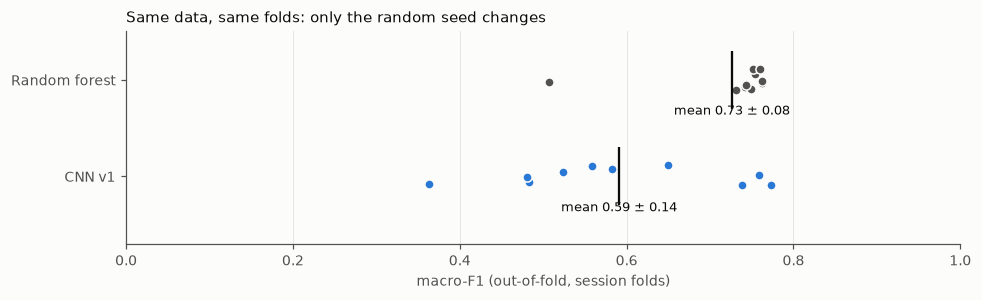

,macro_f1 (seed mean),± sd,macro_f1 (ensemble),session_bal_acc (ensemble),bal_log_loss (ensemble),PD precision (ensemble),false PD alarms (ensemble),recall Partial discharge,recall Switching noise,recall Transient noise,recall Spark lighter
model,,,,,,,,,,,
Random forest (baseline),0.726,0.078,0.757,0.768,0.523,1.000,0,1.0,0.871,0.429,1.0
CNN v1,0.591,0.137,0.585,0.755,1.526,0.228,44,1.0,0.554,0.571,1.0


In [5]:
P = {"CNN v1": cv_cnn_cached(X, files, CNNConfig(), seeds=SEEDS)}
v1_seed, v1_ens = summarise(P["CNN v1"])

fig, ax = plt.subplots(figsize=(9, 2.8))
rng = np.random.default_rng(0)
for i, (name, s) in enumerate([("Random forest", rf_seed), ("CNN v1", v1_seed)]):
    ax.scatter(s["macro_f1"], i + rng.uniform(-0.12, 0.12, len(s)), s=36, color=[INK2, "#2a78d6"][i],
               edgecolor=SURFACE, zorder=3, label=f"{name}: one dot per seed")
    ax.vlines(s["macro_f1"].mean(), i - 0.3, i + 0.3, color=INK, linewidth=1.5, zorder=4)
    ax.text(s["macro_f1"].mean(), i + 0.36, f"mean {s['macro_f1'].mean():.2f} ± {s['macro_f1'].std():.2f}",
            ha="center", fontsize=8.5, color=INK)
ax.set_yticks([0, 1], ["Random forest", "CNN v1"]); ax.set_ylim(-0.5, 1.7); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.set_xlabel("macro-F1 (out-of-fold, session folds)"); ax.grid(axis="y", visible=False)
ax.set_title("Same data, same folds: only the random seed changes", loc="left")
plt.tight_layout(); plt.show()

pd.DataFrame([row("Random forest (baseline)", P_rf), row("CNN v1", P["CNN v1"])]).set_index("model").round(3)

**Explanation:**
- **The seed matters a lot for the CNN.** Its 10 dots spread from **0.36 to 0.77**, while the forest's sit together (apart from seed 6). A single CNN run could have been reported as "0.77, beats the baseline" or "0.36, useless". Both are wrong. (Our own first trial of this CNN, with only 3 seeds, gave an ensemble score of 0.76 and looked as good as the baseline.)
- **Measured properly, the first CNN is clearly behind:** macro-F1 **0.59 ± 0.14** vs **0.73 ± 0.08**, ensemble 0.59 vs 0.76.
- **PD recall is 1.0 for both, but the CNN raises 44 false PD alarms** (PD precision 0.23: fewer than 1 in 4 of its PD calls is a real PD). The forest raises none.
- **Balanced log-loss is 1.53, worse than guessing (1.39).** When the CNN is wrong, it is wrong with near certainty. The forest's 0.52 is far more trustworthy.
- Session-balanced accuracy is close (0.76 vs 0.77). The CNN catches one more transient-noise file (4 of 7 vs 3 of 7) but loses a large switching-noise session. Macro-F1 punishes the latter heavily because 62 files flip together. That is why we look at both scores.

## 5. Where the CNN goes wrong

Each row is one recording session (number of files in brackets), each column one seed. The colour is the share of the session's files predicted correctly.

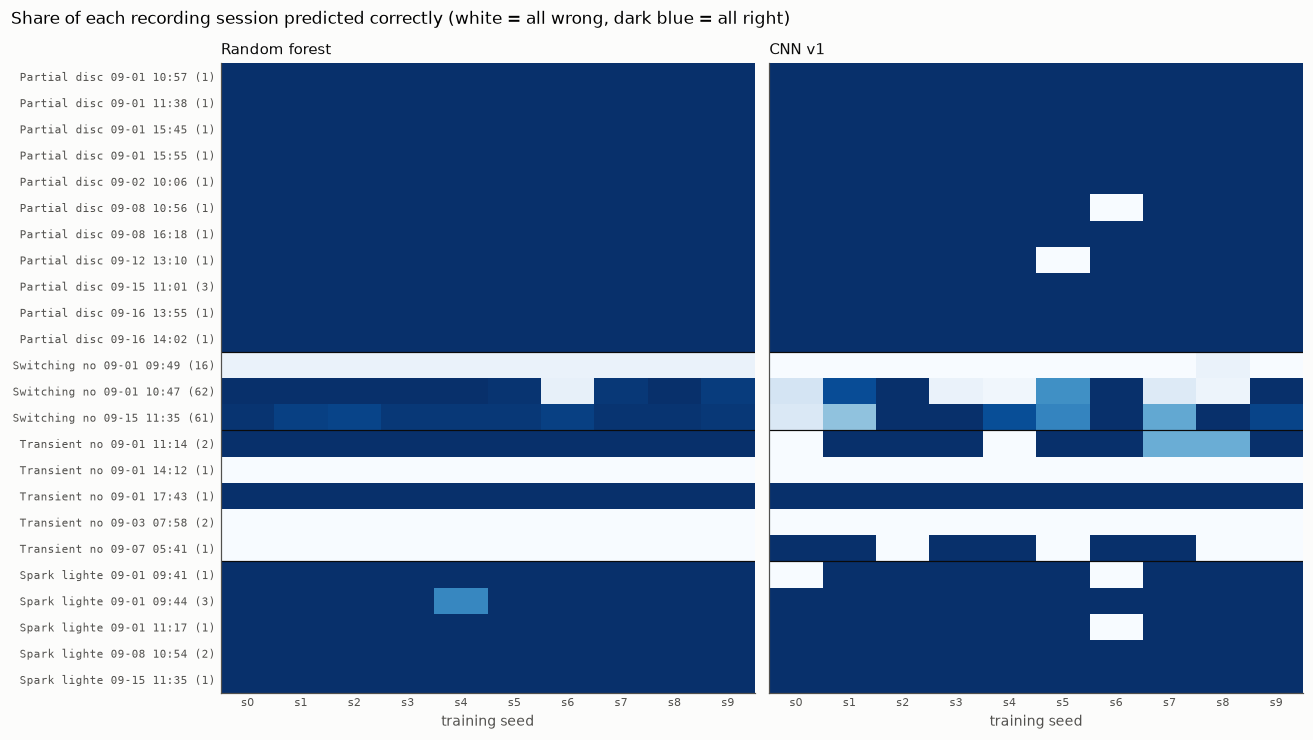

CNN v1, switching session 1 Sep 10:47, all seeds: {'Partial discharge': 296, 'Switching noise': 308, 'Transient noise': 16}


In [6]:
def session_grid(P):
    """Share of each session predicted correctly, for every seed: (sessions x seeds)."""
    ok = pd.DataFrame((P.argmax(2) == y).T, index=sessions)
    g = ok.groupby(level=0).mean()
    lab = files.groupby("session_id")["y"].first()
    order = sorted(g.index, key=lambda s: (lab[s], s))
    return g.loc[order], lab[order]

def plot_grid(ax, P, title):
    g, lab = session_grid(P)
    ax.imshow(g.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    n = files.groupby("session_id").size()
    ax.set_yticks(range(len(g)), [f"{NAMES[CLASSES[l]][:12]:12s} {s.split('@')[1][5:16].replace('T', ' ')} ({n[s]})"
                                  for s, l in zip(g.index, lab)], fontsize=7, family="monospace")
    ax.set_xticks(range(g.shape[1]), [f"s{s}" for s in SEEDS], fontsize=7)
    for i in range(1, len(lab)):
        if lab.iloc[i] != lab.iloc[i - 1]:
            ax.axhline(i - 0.5, color=INK, linewidth=0.8)
    ax.grid(False); ax.tick_params(length=0); ax.set_xlabel("training seed")
    ax.set_title(title, loc="left")

fig, axes = plt.subplots(1, 2, figsize=(12, 6.8), sharey=True)
plot_grid(axes[0], P_rf, "Random forest")
plot_grid(axes[1], P["CNN v1"], "CNN v1")
fig.suptitle("Share of each recording session predicted correctly (white = all wrong, dark blue = all right)",
             x=0.01, ha="left")
plt.tight_layout(); plt.show()

s1047 = files["session_id"].str.contains("10:47").values
print("CNN v1, switching session 1 Sep 10:47, all seeds:",
      {NAMES[CLASSES[c]]: int(n) for c, n in enumerate(np.bincount(P["CNN v1"][:, s1047].argmax(2).ravel(), minlength=4)) if n})

**Explanation:**
- Many rows agree: PD and spark lighter are right for both models (the CNN misses a single file in a few seeds), and both models fail the switching session of **1 Sep 09:49** and the transient sessions of 14:12 and 3 Sep 07:58 (notebook 03, part 5).
- The big difference is the **switching-noise session of 1 Sep 10:47 (62 files)**. The forest gets it right with 9 of 10 seeds. The CNN gets it right with some seeds and wrong with others, and over the 10 seeds it calls these files **PD 296 times out of 620**. Because this one session holds 62 files, it alone moves the CNN's macro-F1 by about ±0.2. That is most of the seed spread in part 4.
- The 15 Sep switching session also wobbles for the CNN (seeds 0, 1, 5, 7), which the forest never does.
- Transient noise is the one place where the CNN does slightly better (the 7 Sep 05:41 file in 6 of 10 seeds).

Why would switching noise be called PD? The next plot compares one file of each over the full 131 µs.

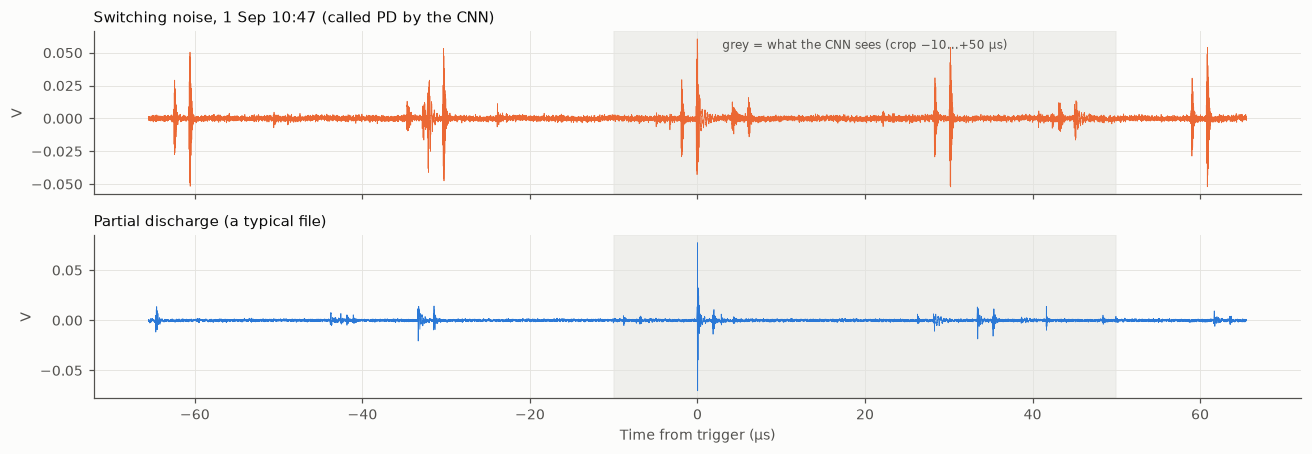

,Switching 10:47,Other switching,Partial discharge
peak,0.061,0.063,0.097
rms,0.003,0.009,0.002
crest,18.783,7.117,38.727
centroid_MHz,20.529,3.515,29.803
band_40_62.5MHz,0.037,0.002,0.392
energy_late,0.367,0.349,0.114


In [7]:
t = (np.arange(X.shape[1]) - TRIGGER) / FS * 1e6
pick = {"Switching noise, 1 Sep 10:47 (called PD by the CNN)": np.flatnonzero(s1047)[0],
        "Partial discharge (a typical file)": np.flatnonzero(files["label"] == "partial_discharge")[1]}
fig, axes = plt.subplots(2, 1, figsize=(12, 4.2), sharex=True)
for ax, (title, i) in zip(axes, pick.items()):
    ax.plot(t, X[i] - np.median(X[i]), color=COLORS[files.at[i, "label"]], linewidth=0.5)
    ax.axvspan(-10, 50, color=GRID, alpha=0.5, zorder=0)
    ax.set_title(title, loc="left"); ax.set_ylabel("V")
axes[0].text(20, axes[0].get_ylim()[1] * 0.8, "grey = what the CNN sees (crop −10…+50 µs)", ha="center", fontsize=8, color=INK2)
axes[-1].set_xlabel("Time from trigger (µs)")
plt.tight_layout(); plt.show()

feat = compute_features(X)
pd.DataFrame({
    "Switching 10:47": feat[s1047].median(),
    "Other switching": feat[(files["label"] == "switching_noise").values & ~s1047].median(),
    "Partial discharge": feat[(files["label"] == "partial_discharge").values].median(),
}).loc[["peak", "rms", "crest", "centroid_MHz", "band_40_62.5MHz", "energy_late"]].round(3)

**Explanation:**
- **Near the trigger, the 10:47 switching file looks like a PD:** one sharp spike of about 0.06 V with fast ringing. Its spectrum is PD-like too (centroid 21 MHz, between other switching noise at 3.5 MHz and PD at 30 MHz).
- **What gives it away is repetition:** the same spike returns every ~31 µs **at the same height**. The PD file also has small background bursts at ±33 µs (switching noise from the same environment), but they are far smaller than its main spike. The forest sees this through features computed over the whole window: the **crest factor** (peak ÷ rms) is 19 for this session vs 39 for PD.
- The CNN sees one repeat inside its crop (at +30 µs), so the clue is available. But when fold 0 is held out, it learns switching noise only from the 09:49 and 15 Sep sessions, which are slow ringing bursts (centroid 1.7 and 3.5 MHz). Nothing in its training says "a PD-like spike that repeats at equal height is switching noise". Whether it happens to pick up that rule depends on the seed.
- The forest gets this knowledge for free: its hand-made features encode what the EDA taught us. The CNN must learn it from examples, and we have only 3 switching sessions.

## 6. Ten attempts to improve the CNN

Each attempt changes **one thing** and is scored with the rules from part 1. Attempts 2–10 each change one setting relative to attempt 1.

| # | Change | Idea |
|---|---|---|
| 1 | **session-balanced sampler** (`session_balanced_sampler` in `dataset/torch_data.py`) | inside each class, draw every recording session equally often. Otherwise a 61-file session dominates switching noise and the odd 16-file session is rarely drawn |
| 2 | + light augmentation | each time a file is drawn: random shift of up to ±1 µs and 0.5 mV of extra noise, so repeated draws are not identical copies |
| 3 | + stronger regularisation | weight decay 0.1 (was 0.01) and dropout 0.5 (was 0.3): pushes towards simpler models that memorise less |
| 4 | + slower, longer training | learning rate 0.001 (was 0.003), 80 epochs (was 40) |
| 5 | full 131 µs window | the CNN sees all the repeated switching bursts (part 5) |
| 6 | full window, log input | `sign(x)·log(1 + |x| / 1 mV)`: keeps amplitude but compresses it, so small ringing stays visible next to big spikes |
| 7 | shape only | peak-normalised input, the test proposed in notebook 03. Target: **0.56**, the forest on shape features only |
| 8 | shape + 3 amplitude numbers | peak-normalised waveform, plus log peak, log rms and clipped share fed straight to the last layer: amplitude is used, but openly |
| 9 | CNN + the 14 baseline features | the forest's 14 features (log, standardised) fed to the last layer next to the CNN's 128 numbers |
| 10 | 9 + light augmentation | |

An earlier quick screening with 3 seeds also tried stronger augmentation (gain ±25% and polarity flip), label smoothing, a smaller network (8 channels), 20 epochs and log input on the short crop. None looked better, so they are not repeated here.

In [8]:
EXPERIMENTS = {
    "1  session sampler":           CNNConfig(sampler="session"),
    "2  + light augmentation":      CNNConfig(sampler="session", augment="light"),
    "3  + stronger regularisation": CNNConfig(sampler="session", weight_decay=0.1, dropout=0.5),
    "4  + slower, longer training": CNNConfig(sampler="session", lr=1e-3, epochs=80),
    "5  full 131 µs window":        CNNConfig(sampler="session", crop=None),
    "6  full window, log input":    CNNConfig(sampler="session", crop=None, normalize="log"),
    "7  shape only (peak-norm.)":   CNNConfig(sampler="session", normalize="peak"),
    "8  shape + 3 amplitude numbers": CNNConfig(sampler="session", normalize="peak", extra="amplitude"),
    "9  CNN + 14 baseline features": CNNConfig(sampler="session", extra="features"),
    "10 CNN + 14 features + light aug": CNNConfig(sampler="session", extra="features", augment="light"),
}
for name, c in EXPERIMENTS.items():
    print(f"{name:34s}", end=" ")
    P[name] = cv_cnn_cached(X, files, c, seeds=SEEDS)

table = pd.DataFrame([row("Random forest (baseline)", P_rf)] + [row(n, p) for n, p in P.items()]).set_index("model")
table.round(3)

1  session sampler                 loaded from cache
2  + light augmentation            loaded from cache
3  + stronger regularisation       loaded from cache
4  + slower, longer training       loaded from cache
5  full 131 µs window              loaded from cache
6  full window, log input          loaded from cache
7  shape only (peak-norm.)         loaded from cache
8  shape + 3 amplitude numbers     loaded from cache
9  CNN + 14 baseline features      loaded from cache
10 CNN + 14 features + light aug   loaded from cache


,macro_f1 (seed mean),± sd,macro_f1 (ensemble),session_bal_acc (ensemble),bal_log_loss (ensemble),PD precision (ensemble),false PD alarms (ensemble),recall Partial discharge,recall Switching noise,recall Transient noise,recall Spark lighter
model,,,,,,,,,,,
Random forest (baseline),0.726,0.078,0.757,0.768,0.523,1.000,0,1.0,0.871,0.429,1.000
CNN v1,0.591,0.137,0.585,0.755,1.526,0.228,44,1.0,0.554,0.571,1.000
1 session sampler,0.609,0.111,0.561,0.740,1.281,0.181,59,1.0,0.475,0.571,1.000
2 + light augmentation,0.560,0.077,0.553,0.736,0.860,0.173,62,1.0,0.453,0.571,1.000
3 + stronger regularisation,0.590,0.124,0.544,0.715,1.025,0.181,59,1.0,0.475,0.429,1.000
"4 + slower, longer training",0.589,0.154,0.552,0.720,1.044,0.191,55,1.0,0.504,0.571,0.875
5 full 131 µs window,0.545,0.117,0.550,0.736,1.496,0.178,60,1.0,0.453,0.571,1.000
"6 full window, log input",0.420,0.059,0.478,0.639,1.064,0.178,60,1.0,0.468,0.286,0.875
7 shape only (peak-norm.),0.397,0.179,0.507,0.571,0.995,0.812,3,1.0,0.511,0.429,0.500


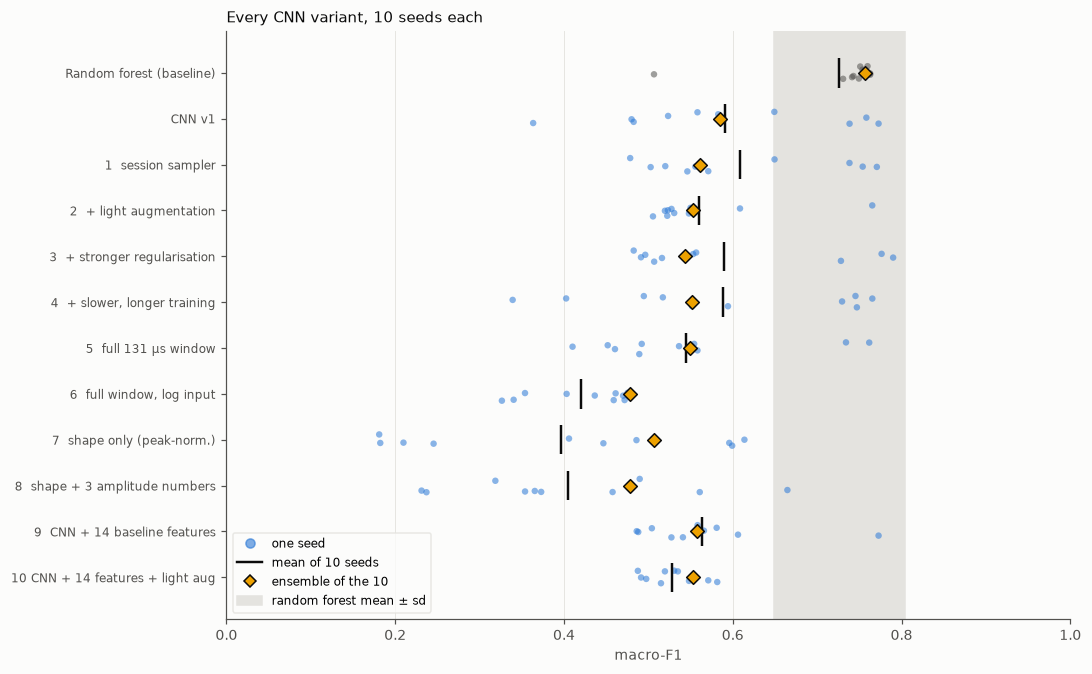

In [9]:
names = ["Random forest (baseline)"] + list(P)
fig, ax = plt.subplots(figsize=(10, 6.2))
rng = np.random.default_rng(0)
for i, n in enumerate(names):
    PP = P_rf if i == 0 else P[n]
    f1 = [metrics(y, p.argmax(1))["macro_f1"] for p in PP]
    color = INK2 if i == 0 else "#2a78d6"
    ax.scatter(f1, i + rng.uniform(-0.15, 0.15, len(f1)), s=18, color=color, alpha=0.55, edgecolor="none", zorder=3)
    ax.vlines(np.mean(f1), i - 0.32, i + 0.32, color=INK, linewidth=1.6, zorder=4)
    ax.scatter(table.loc[n, "macro_f1 (ensemble)"], i, marker="D", s=40, color="#eda100", edgecolor=INK, zorder=5)
ax.axvspan(rf_seed["macro_f1"].mean() - rf_seed["macro_f1"].std(), rf_seed["macro_f1"].mean() + rf_seed["macro_f1"].std(),
           color=GRID, zorder=0)
ax.set_yticks(range(len(names)), names, fontsize=8); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.set_xlabel("macro-F1"); ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Line2D([], [], color="#2a78d6", marker="o", linestyle="", alpha=0.6, label="one seed"),
                   plt.Line2D([], [], color=INK, linewidth=1.6, label="mean of 10 seeds"),
                   plt.Line2D([], [], color="#eda100", marker="D", linestyle="", markeredgecolor=INK, label="ensemble of the 10"),
                   Patch(color=GRID, label="random forest mean ± sd")],
          loc="lower left", fontsize=8, frameon=True, facecolor=SURFACE, edgecolor=GRID)
ax.set_title("Every CNN variant, 10 seeds each", loc="left")
plt.tight_layout(); plt.show()

**Explanation:**
- **No attempt passes the improvement rule.** The best seed mean is attempt 1 (session sampler), **0.61 vs 0.59**. That +0.02 is well inside the ±0.04 uncertainty, and its ensemble, session-balanced and PD-precision scores are slightly *lower*. Every CNN stays left of the forest's grey band.
- **Without volts the CNN is clearly worse** (attempts 6–8: 0.40–0.42). The shape-only CNN scores **0.40**, below the forest on 11 shape features (**0.56**). Notebook 03 hoped a CNN would extract more shape information than 11 summary numbers. On this data it does not. One detail: the shape-only CNN is the only variant that does *not* call the 10:47 session PD (3 false PD alarms instead of 44–62). Instead it confuses switching noise with spark lighter, as the shape-only forest did.
- **The full window does not help** (attempt 5: 0.55), even though it holds 4–5 repeats of every switching burst. Each output position sees only ~25 µs, so no filter spans two bursts, and two training sessions are too few to learn "repeats at equal height" through the averaging step.
- **Augmentation and regularisation make the CNN steadier, not better.** Attempt 10 has the smallest spread (±0.03) and attempt 9 the best log-loss (0.75 vs 1.53), so it is much less often confidently wrong. Macro-F1 does not rise.
- **Attempt 9 is the clearest lesson.** The CNN with all 14 baseline features (0.56) is *worse* than the forest on those 14 features alone (0.73). The 128 numbers the CNN learns from the waveform describe the training sessions very well and new sessions badly, so adding them hurts.
- PD recall stays at 13 of 13 in every attempt. The errors are always in the noise classes.

## 7. Final comparison

There is no clear winner among the CNNs, so we compare the baseline with two of them: **CNN v1** (the simplest) and **attempt 1** (session sampler, the best 10-seed mean). All three use the 10-seed ensemble. The table below gives macro-F1 per fold.

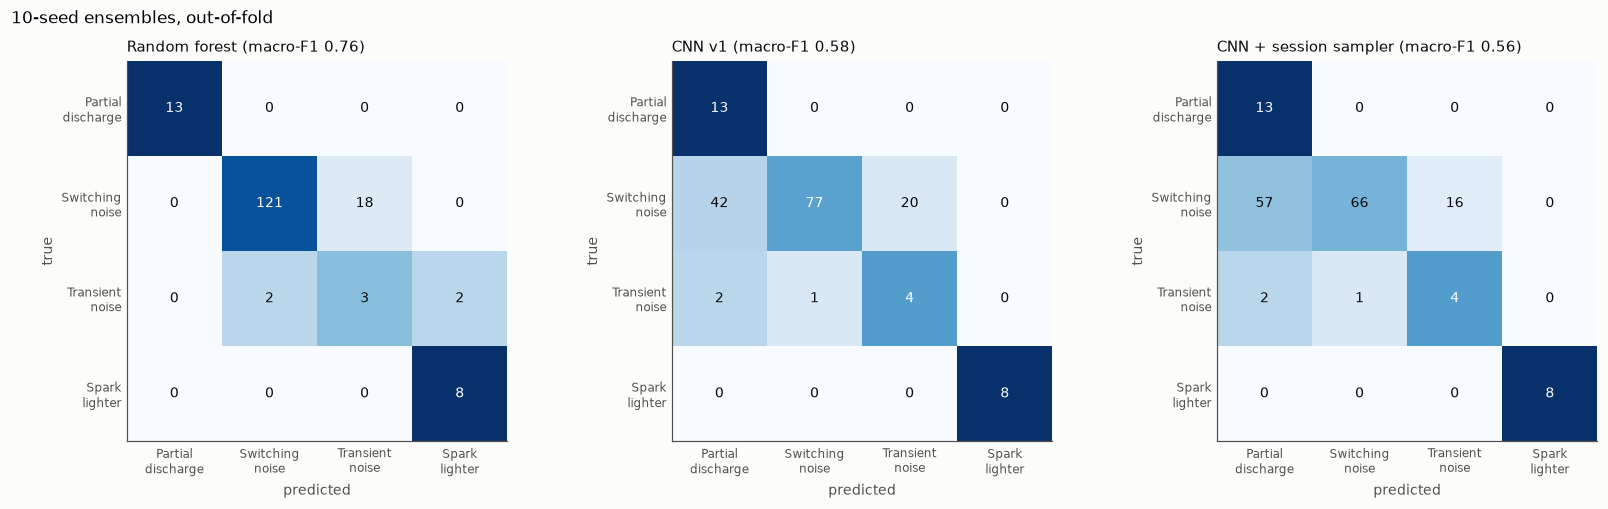

,fold 0,fold 1,fold 2
Random forest,0.915,0.660,0.578
CNN v1,0.577,0.692,0.568
CNN + session sampler,0.484,0.700,0.568


In [10]:
FINAL = "1  session sampler"
shown = {"Random forest": P_rf, "CNN v1": P["CNN v1"], "CNN + session sampler": P[FINAL]}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (name, PP) in zip(axes, shown.items()):
    confusion_plot(ax, confusion(y, PP.mean(0).argmax(1)), f"{name} (macro-F1 {scores(PP.mean(0))['macro_f1']:.2f})")
fig.suptitle("10-seed ensembles, out-of-fold", x=0.01, ha="left")
plt.tight_layout(); plt.show()

per_fold = pd.DataFrame({
    m: {f"fold {k}": metrics(y[files["fold"] == k], PP.mean(0).argmax(1)[files["fold"] == k])["macro_f1"] for k in range(3)}
    for m, PP in shown.items()}).T
per_fold.round(3)

**Explanation:**
- **Partial discharge:** all three catch 13 of 13.
- **False PD alarms decide the comparison:** the CNNs call **42–57 switching-noise files PD**, all from the 10:47 session. The forest calls none. In a monitoring system, a PD alarm that is wrong 3 times out of 4 would soon be ignored.
- **Transient noise** is the only class where the CNNs are ahead, 4 of 7 vs 3 of 7. With 7 files, that is one file.
- **Per fold:** the CNNs lose nearly all their ground in **fold 0** (0.48–0.58 vs 0.92), the fold whose switching noise is the 10:47 session. In folds 1 and 2 they are level with the forest (0.69–0.70 vs 0.66 in fold 1, 0.57 vs 0.58 in fold 2). So the gap comes from one session the CNN has no way to learn from the other two.

## 8. Save the results

Written to `models/cnn/` in the data root, next to `models/baseline/`:
- `results.csv`: every score of every model in the table of part 6;
- `config.json`: the settings of every variant, the seeds and the thread count (results depend slightly on the number of CPU threads, so it is fixed in `cnn.THREADS`);
- `oof_proba.npz`: the out-of-fold probabilities (10 seeds × 167 files × 4 classes) of the forest, CNN v1 and the session-sampler CNN, for later comparisons without retraining.

In [11]:
out = ensure_dirs()["models"] / "cnn"
out.mkdir(exist_ok=True)
table.rename_axis("model").reset_index().to_csv(out / "results.csv", index=False)
np.savez(out / "oof_proba.npz", random_forest=P_rf, cnn_v1=P["CNN v1"], cnn_session_sampler=P[FINAL])
(out / "config.json").write_text(json.dumps({
    "split": "session folds from the database (ureca.dataset.folds)",
    "n_files": int(len(files)),
    "seeds": list(SEEDS), "torch_threads": THREADS,
    "first_cnn": CNNConfig().to_dict(),
    "best_cnn": {"name": FINAL, **EXPERIMENTS[FINAL].to_dict()},
    "experiments": {n: c.changes() for n, c in EXPERIMENTS.items()},
    "main_score": "macro-F1 of out-of-fold predictions, mean +- sd over 10 seeds, and of the 10-seed ensemble",
    "also_reported": ["session-balanced accuracy", "balanced log-loss", "PD recall", "PD precision"],
}, indent=2, default=str))
print("saved to", out)

saved to C:\Users\Thyme\OneDrive - Nanyang Technological University\URECA_project_root\models\cnn


## 9. Summary and next steps

| (session folds, 10 seeds) | macro-F1 mean ± sd | macro-F1 ensemble | session-bal. acc. | bal. log-loss | false PD alarms |
|---|---|---|---|---|---|
| **Random forest, 14 features** (notebook 03) | **0.73 ± 0.08** | **0.76** | **0.77** | **0.52** | **0** |
| CNN v1 (volts) | 0.59 ± 0.14 | 0.59 | 0.76 | 1.53 | 44 |
| CNN + session sampler (best 10-seed mean) | 0.61 ± 0.11 | 0.56 | 0.74 | 1.28 | 59 |
| CNN + 14 features (best log-loss) | 0.56 ± 0.08 | 0.56 | 0.74 | 0.75 | 60 |
| CNN, shape only | 0.40 ± 0.18 | 0.51 | 0.57 | 1.00 | 3 |

What we learnt:
1. **On this data the CNN does not beat the baseline**, and none of ten targeted changes closed the gap. The random forest stays the working model.
2. **One CNN run is not a result.** With the same settings, the seed alone moved macro-F1 between 0.36 and 0.77. Our first 3-seed trial looked as good as the baseline. Always report the mean ± sd over 10 seeds and the ensemble score. This applies to every later model too.
3. **The gap is one recording session, and it is a data problem.** Switching noise comes from only 3 sessions. In each round the CNN learns it from two and must recognise a third that looks different. The forest's hand-made features carry what the EDA found (repetition across the window, crest factor). The CNN would have to learn it from examples we do not have.
4. **The CNN is overconfident:** its log-loss is worse than guessing, so its probabilities should not be used as alarm confidence.
5. **The CNN also leans on amplitude:** without volts it falls to 0.40, below the forest's 0.56 on shape features.

Next steps, most useful first:
1. **Record more sessions**, above all switching and transient noise from other days, loads and setups. This is the only change likely to help both models, and with ≥5 switching sessions we could also use more folds.
2. **Use the next batch as a true test set** for the forest and the CNN exactly as they are now (settings and probabilities are saved), before any re-tuning.
3. **CNN ideas once there is more data:** a longer field of view (dilated convolutions, so one filter spans more than 33 µs and can see bursts repeat), spectrogram input (EDA part 9), and self-supervised pre-training on unlabelled field recordings, which fits the "self-learning" goal of the project.